# **Step 5 of 7: OPTICS Clustering (HR Employees)**

**OPTICS** (Ordering Points To Identify the Clustering Structure) is like DBSCAN, but it **does not need one fixed `eps`**. Instead it orders all points and gives every point a **reachability distance**. The result is the **reachability plot**:
- **valleys** (low reachability) = dense clusters
- **peaks** (high reachability) = gaps between clusters, or noise

From this one plot, clusters can be taken out in two ways:
1. **`xi` method:** find valleys by looking for steep drops / rises in the plot (`xi` = how steep; `min_cluster_size` = smallest cluster)
2. **`dbscan-cut` method:** cut the plot with a horizontal line at height `eps`. This is the same as running DBSCAN, but many `eps` values can be tried quickly from **one** OPTICS run.

Main parameters: `min_samples` (points needed for a dense region), `xi`, `min_cluster_size`, `eps` (for the cut).

Good for: seeing the density structure, clusters with different densities, noise detection. Weak for: slower than DBSCAN, the `xi` method needs clear steep valleys.

### 1. Import and load the preprocessed data
This notebook uses the files made in **step 1 (01_HR_Data_Preprocessing)**:
- `hr_clean.csv`: cleaned data in original units (used to describe the clusters)
- `hr_preprocessed.csv`: scaled clustering features (used by the algorithm)
- `hr_scaler.pkl`, `preprocessing_info.json` (and `hr_truth.csv`, demo data only)

Keep these files in the same folder as this notebook.

> The data is **synthetic demo data** (about 4 hidden employee groups + 3% unusual employees). Because we know the hidden groups, the result can also be checked with *external* metrics. With real HR data this check is not possible and only the internal metrics are used.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_completeness_v_measure)
sns.set_theme(style='whitegrid')

# ---- files made by 01_HR_Data_Preprocessing.ipynb (keep them in the same folder) ----
need = ['hr_clean.csv', 'hr_preprocessed.csv', 'preprocessing_info.json', 'hr_scaler.pkl']
missing = [f for f in need if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f'Run 01_HR_Data_Preprocessing.ipynb first. Missing files: {missing}')

info = json.load(open('preprocessing_info.json'))
FEATURES, PROFILE_COLS = info['features'], info['profile_cols']

df = pd.read_csv('hr_clean.csv')                    # cleaned data, original units (used to describe the clusters)
X_df = pd.read_csv('hr_preprocessed.csv')           # scaled features (used by the algorithm)
assert (df['employee_id'].values == X_df['employee_id'].values).all(), 'files do not match'
X = X_df[FEATURES].values
scaler = joblib.load('hr_scaler.pkl')               # needed to prepare NEW employees

# hidden true groups: exist only in the synthetic demo data, used only to check the result at the end
if os.path.exists('hr_truth.csv'):
    df = df.merge(pd.read_csv('hr_truth.csv'), on='employee_id', how='left')
HAS_TRUTH = 'segment_true' in df.columns

print('Employees:', X.shape[0], '| clustering features:', FEATURES)
print('Hopkins statistic from step 1:', info['hopkins'], '| hidden truth available:', HAS_TRUTH)
df.head()

Employees: 1498 | clustering features: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company']
Hopkins statistic from step 1: 0.747 | hidden truth available: True


,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,work_accident,promotion_last_5years,department,left,is_outlier_iqr,segment_true
0,1456,0.87,0.92,4.0,178.0,5.0,1,1,0,technical,0,0,Engaged high performers
1,1957,0.62,0.68,5.0,150.0,10.0,1,1,1,technical,0,0,Loyal long-tenure
2,1612,0.71,0.93,5.0,191.0,4.0,1,0,0,sales,1,0,Engaged high performers
3,1998,0.64,0.73,3.0,180.0,9.0,1,0,0,support,0,0,Loyal long-tenure
4,2037,0.35,0.51,2.0,169.0,2.0,2,0,0,sales,0,0,Disengaged underused


Helper functions used in all sections (metrics, plots, cluster profile):

In [2]:
def internal_metrics(X, labels):
    """Internal metrics (no true labels needed). Noise points (-1) are ignored."""
    labels = np.asarray(labels); mask = labels != -1
    n_clusters = len(set(labels[mask]))
    out = {'n_clusters': n_clusters, 'noise_%': round(100 * (~mask).mean(), 1),
           'silhouette': np.nan, 'calinski_harabasz': np.nan, 'davies_bouldin': np.nan}
    if n_clusters >= 2 and mask.sum() > n_clusters:
        out['silhouette'] = silhouette_score(X[mask], labels[mask])
        out['calinski_harabasz'] = calinski_harabasz_score(X[mask], labels[mask])
        out['davies_bouldin'] = davies_bouldin_score(X[mask], labels[mask])
    return out

def external_metrics(truth, labels):
    """External metrics: compare with the hidden true segments (demo data only)."""
    h, c, v = homogeneity_completeness_v_measure(truth, labels)
    return {'ARI': adjusted_rand_score(truth, labels), 'NMI': normalized_mutual_info_score(truth, labels),
            'homogeneity': h, 'completeness': c, 'v_measure': v}

def plot_clusters(Z, labels, ax, title, centers=None):
    """2D scatter of the clusters (Z = PCA coordinates). Noise = black x."""
    labels = np.asarray(labels); palette = sns.color_palette('tab10', 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(Z[m, 0], Z[m, 1], c='black', marker='x', s=25, label=f'Noise ({m.sum()})')
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.7, color=palette[lab % 10], label=f'Cluster {lab} ({m.sum()})')
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='*', s=300, edgecolor='k', label='Centers')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.legend(fontsize=8)

def cluster_profile(data, labels):
    """Average of every feature in each cluster (original units) + size."""
    labels = np.asarray(labels)
    prof = data[PROFILE_COLS].assign(cluster=labels).groupby('cluster').mean()
    prof['size'] = pd.Series(labels).value_counts().sort_index()
    prof['share_%'] = (100 * prof['size'] / len(labels)).round(1)
    return prof

def plot_profile(prof, title='Cluster profile (colour = high / low compared with other clusters, number = real average)'):
    feat = prof[PROFILE_COLS]
    z = (feat - feat.mean()) / (feat.std(ddof=0) + 1e-9)
    plt.figure(figsize=(9, 0.9 * len(prof) + 2))
    sns.heatmap(z, annot=feat.round(2), fmt='g', cmap='RdYlGn', center=0, cbar_kws={'label': 'relative level'})
    plt.title(title); plt.ylabel('Cluster'); plt.tight_layout(); plt.show()

### 2. Look at the data

In [3]:
df[PROFILE_COLS].describe().round(2)

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level
count,1498.00,1498.00,1498.00,1498.00,1498.00,1498.00
mean,0.55,0.73,4.12,196.67,4.76,0.93
std,0.23,0.16,1.45,47.51,2.24,0.74
min,0.09,0.36,2.00,96.00,2.00,0.00
25%,0.35,0.60,3.00,160.00,3.00,0.00
50%,0.57,0.77,4.00,191.00,4.00,1.00
75%,0.76,0.86,5.00,222.00,6.00,1.00
max,1.00,1.00,7.00,310.00,10.00,2.00


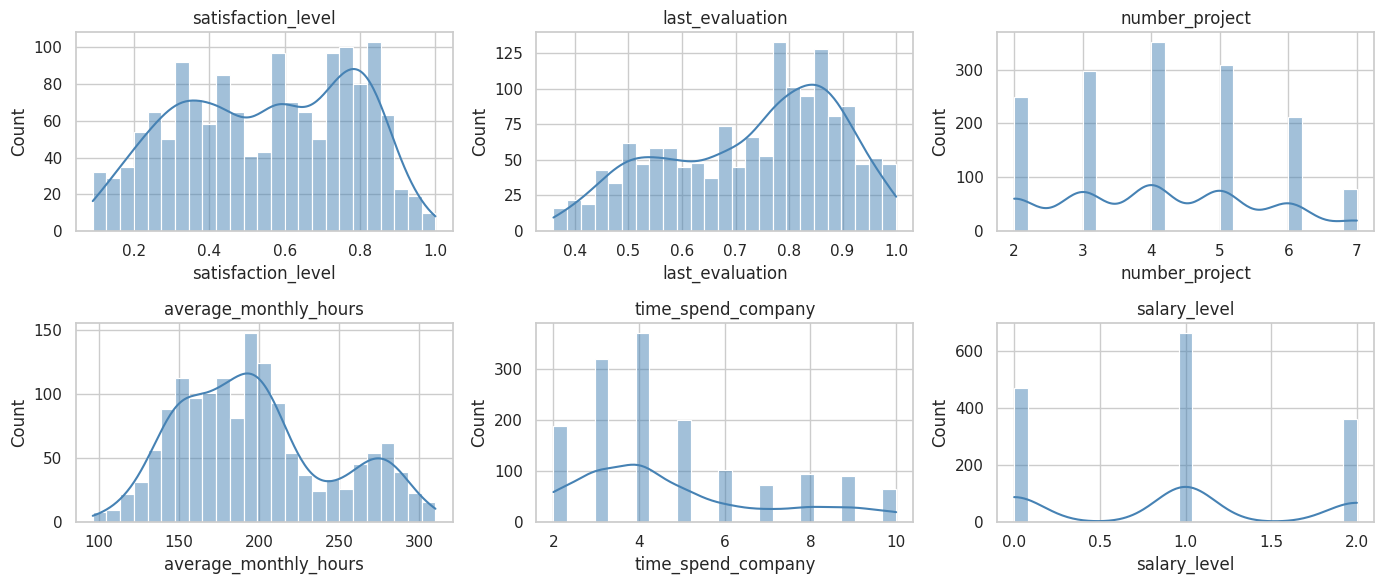

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, f in zip(ax.ravel(), PROFILE_COLS):
    sns.histplot(df[f], bins=25, kde=True, ax=a, color='steelblue')
    a.set_title(f)
plt.tight_layout(); plt.show()

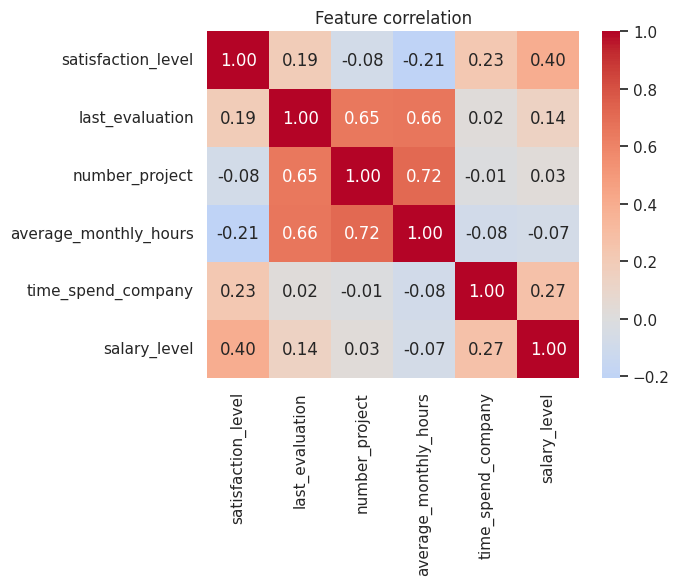

In [5]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[PROFILE_COLS].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlation'); plt.show()

### 3. 2D view for plotting (PCA)
The data is already **cleaned and scaled in step 1**, so no preprocessing is needed here. PCA is used **only to draw** the clusters in 2D (the clustering itself uses all features).

In [6]:
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
print('Variance explained by the 2 plotted components:', (pca.explained_variance_ratio_.sum() * 100).round(1), '%')

Variance explained by the 2 plotted components: 72.9 %


### 4. Tune the parameters (grid search)
For every `min_samples`, OPTICS is run **once**. From that single run we extract clusters with both methods and many settings, and judge each with **internal metrics** + number of clusters + % noise.

In [7]:
from sklearn.cluster import OPTICS, cluster_optics_dbscan, cluster_optics_xi

In [8]:
# Selection rule: 2 to 8 clusters, at most 20% noise, then the best silhouette.
# (Silhouette alone would prefer 'a tiny dense cluster + almost everything else noise', so the rule keeps the result useful.)
# If nothing fits, the rule is relaxed step by step.
def pick_best(res, max_noise=20, min_c=2, max_c=8):
    res = res.dropna(subset=['silhouette'])
    for noise, cmin, cmax in [(max_noise, min_c, max_c), (35, min_c, 12), (60, 2, 20)]:
        ok = res[(res['n_clusters'] >= cmin) & (res['n_clusters'] <= cmax) & (res['noise_%'] <= noise)]
        if len(ok):
            return ok.sort_values('silhouette', ascending=False)
    return res.sort_values('silhouette', ascending=False)

In [9]:
%%time
rows = []
for ms in [10, 20, 30]:
    base = OPTICS(min_samples=ms).fit(X)                       # one OPTICS run per min_samples

    # method 1: horizontal cut of the reachability plot (DBSCAN-style)
    for eps in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2]:
        lab = cluster_optics_dbscan(reachability=base.reachability_, core_distances=base.core_distances_,
                                    ordering=base.ordering_, eps=eps)
        rows.append({'method': 'dbscan-cut', 'min_samples': ms, 'eps': eps, 'xi': np.nan, 'min_cluster_size': np.nan,
                     **internal_metrics(X, lab)})

    # method 2: steep valleys (xi)
    for xi in [0.01, 0.03, 0.05, 0.1]:
        for mcs in [0.02, 0.05]:
            lab, _ = cluster_optics_xi(reachability=base.reachability_, predecessor=base.predecessor_,
                                       ordering=base.ordering_, min_samples=ms, min_cluster_size=mcs, xi=xi)
            rows.append({'method': 'xi', 'min_samples': ms, 'eps': np.nan, 'xi': xi, 'min_cluster_size': mcs,
                         **internal_metrics(X, lab)})
grid = pd.DataFrame(rows)
print('Settings tried:', len(grid))
print('\nBest of each method (by the selection rule):')
display(pd.concat([pick_best(grid[grid['method'] == m_]).head(3) for m_ in ['dbscan-cut', 'xi']]).round(3))

Settings tried: 45

Best of each method (by the selection rule):


,method,min_samples,eps,xi,min_cluster_size,n_clusters,noise_%,silhouette,calinski_harabasz,davies_bouldin
33,dbscan-cut,30,0.8,NaN,NaN,4,15.4,0.532,1802.527,0.730
18,dbscan-cut,20,0.8,NaN,NaN,3,10.1,0.480,1288.979,0.792
3,dbscan-cut,10,0.8,NaN,NaN,3,6.7,0.471,1270.470,0.801
39,xi,30,NaN,0.03,0.02,3,3.9,0.462,1260.801,0.818
40,xi,30,NaN,0.03,0.05,3,3.9,0.462,1260.801,0.818


CPU times: user 3.46 s, sys: 19.1 ms, total: 3.48 s
Wall time: 3.53 s


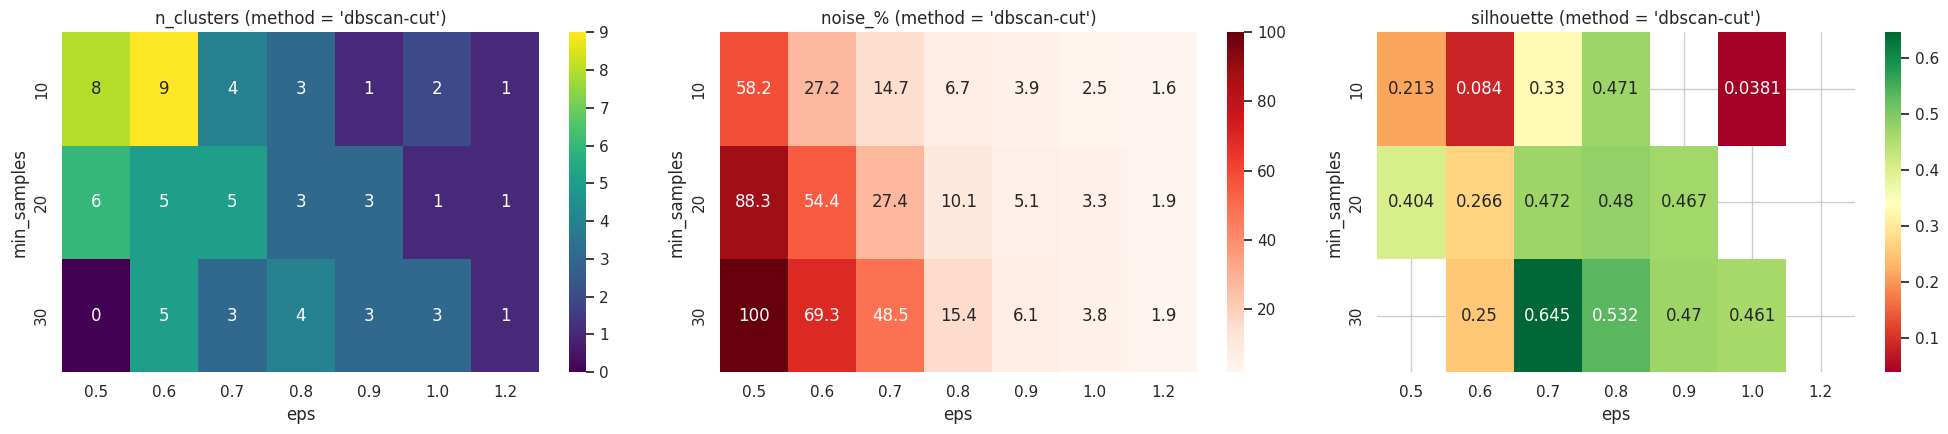

Method 'xi': clusters found per setting (n_clusters) and % noise


n_clusters                noise_%              \
xi                                 0.01 0.03 0.05 0.10    0.01  0.03  0.05   
min_samples min_cluster_size                                                 
10          0.02                   12.0  6.0  2.0  1.0    60.1  69.6  88.5   
            0.05                    6.0  3.0  1.0  1.0    49.0  68.4  90.6   
20          0.02                    9.0  3.0  1.0  1.0    75.9  73.3   0.0   
            0.05                    5.0  3.0  1.0  1.0    52.8  58.1   0.0   
30          0.02                    6.0  3.0  1.0  1.0    71.3   3.9   0.0   
            0.05                    5.0  3.0  1.0  1.0    54.1   3.9   0.0   

                                   
xi                           0.10  
min_samples min_cluster_size       
10          0.02              0.0  
            0.05              0.0  
20          0.02              0.0  
            0.05              0.0  
30          0.02              0.0  
            0.05              0.0

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
cut = grid[grid['method'] == 'dbscan-cut']
for a, col, cmap in zip(ax, ['n_clusters', 'noise_%', 'silhouette'], ['viridis', 'Reds', 'RdYlGn']):
    sns.heatmap(cut.pivot(index='min_samples', columns='eps', values=col), annot=True, fmt='.3g', cmap=cmap, ax=a)
    a.set_title(f"{col} (method = 'dbscan-cut')")
plt.tight_layout(); plt.show()

xi_part = grid[grid['method'] == 'xi']
print("Method 'xi': clusters found per setting (n_clusters) and % noise")
display(xi_part.pivot_table(index=['min_samples', 'min_cluster_size'], columns='xi', values=['n_clusters', 'noise_%']).round(1))

### 5. Final OPTICS model
The setting with the best result under the selection rule is used (change the values to try others).

In [11]:
best = pick_best(grid).iloc[0]
METHOD, MIN_SAMPLES = best['method'], int(best['min_samples'])

if METHOD == 'dbscan-cut':
    EPS = float(best['eps'])
    optics = OPTICS(min_samples=MIN_SAMPLES, cluster_method='dbscan', eps=EPS).fit(X)
    print(f"method = dbscan-cut | min_samples = {MIN_SAMPLES} | eps = {EPS}")
else:
    XI, MIN_CLUSTER = float(best['xi']), float(best['min_cluster_size'])
    optics = OPTICS(min_samples=MIN_SAMPLES, xi=XI, min_cluster_size=MIN_CLUSTER).fit(X)
    print(f"method = xi | min_samples = {MIN_SAMPLES} | xi = {XI} | min_cluster_size = {MIN_CLUSTER}")

labels = optics.labels_
print(pd.Series(labels).value_counts().sort_index().rename('employees').to_string())

method = dbscan-cut | min_samples = 30 | eps = 0.8
-1    230
 0    424
 1    253
 2    342
 3    249


### 6. Reachability plot
Employees are on the x-axis in the OPTICS order; the height is the reachability distance. Each **valley** is a group of dense, close employees; the coloured bars are the clusters found, black = noise. The grey dashed line shows the `eps` of the horizontal cut (if that method is used).

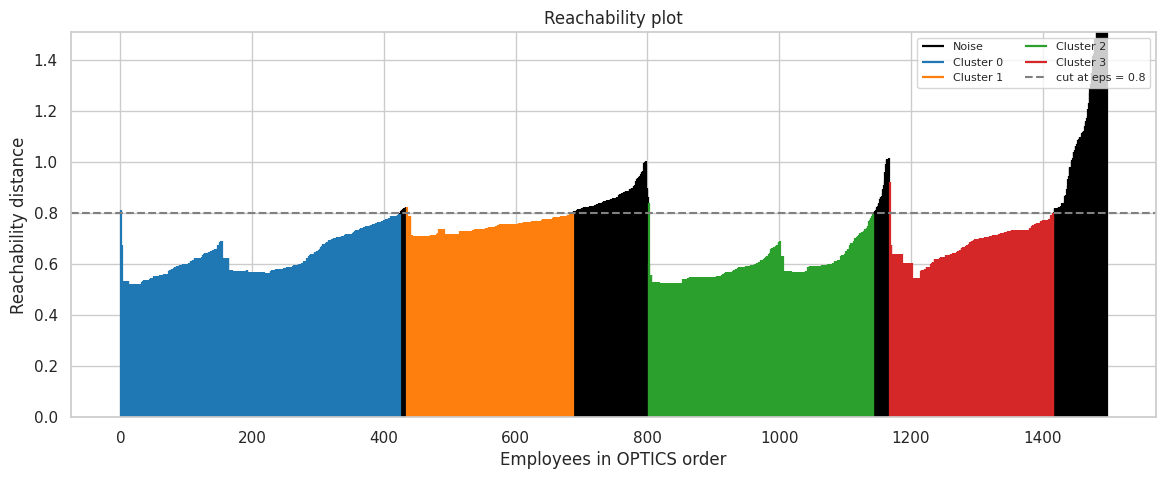

In [12]:
space = np.arange(len(X))
reach = optics.reachability_[optics.ordering_]
lab_ord = labels[optics.ordering_]
reach_plot = np.where(np.isinf(reach), np.nan, reach)

plt.figure(figsize=(14, 5))
for c in sorted(set(lab_ord)):
    m = lab_ord == c
    plt.vlines(space[m], 0, np.nan_to_num(reach_plot[m]), linewidth=1.6,
               color='black' if c == -1 else sns.color_palette('tab10')[c % 10],
               label='Noise' if c == -1 else f'Cluster {c}')
if METHOD == 'dbscan-cut':
    plt.axhline(EPS, color='gray', ls='--', label=f'cut at eps = {EPS}')
plt.ylabel('Reachability distance'); plt.xlabel('Employees in OPTICS order'); plt.title('Reachability plot')
plt.ylim(0, np.nanpercentile(reach_plot, 99)); plt.legend(fontsize=8, ncol=2); plt.show()

### 7. Evaluation metrics

In [13]:
metrics = internal_metrics(X, labels)
print('===== INTERNAL METRICS (no true labels needed; noise points are ignored) =====')
print('Clusters found     :', metrics['n_clusters'], '| noise points:', metrics['noise_%'], '%')
print('Silhouette         :', round(metrics['silhouette'], 4), ' (higher is better)')
print('Calinski-Harabasz  :', round(metrics['calinski_harabasz'], 1), ' (higher is better)')
print('Davies-Bouldin     :', round(metrics['davies_bouldin'], 4), ' (lower is better)')

if HAS_TRUTH:
    ext = external_metrics(df['segment_true'], labels)
    print('\n===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====')
    for k_, v_ in ext.items():
        print(f'{k_:<13}: {v_:.4f}')

===== INTERNAL METRICS (no true labels needed; noise points are ignored) =====
Clusters found     : 4 | noise points: 15.4 %
Silhouette         : 0.5324  (higher is better)
Calinski-Harabasz  : 1802.5  (higher is better)
Davies-Bouldin     : 0.7301  (lower is better)

===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====
ARI          : 0.7531
NMI          : 0.7508
homogeneity  : 0.7792
completeness : 0.7244
v_measure    : 0.7508


### 8. Visualization
Black **x** = noise.

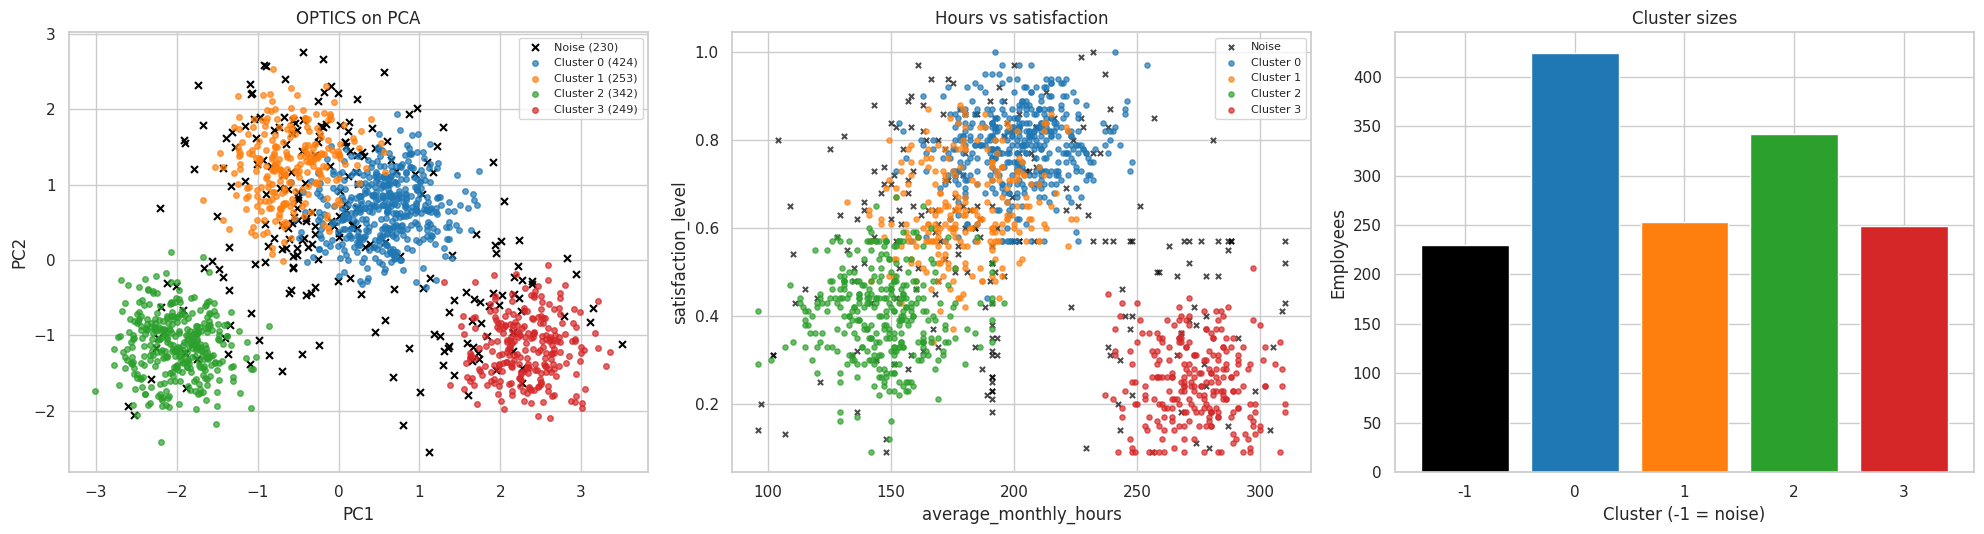

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
plot_clusters(Z, labels, ax[0], 'OPTICS on PCA')

for c in sorted(set(labels)):
    m = labels == c
    ax[1].scatter(df.loc[m, 'average_monthly_hours'], df.loc[m, 'satisfaction_level'], s=14, alpha=0.7,
                  color='black' if c == -1 else sns.color_palette('tab10')[c % 10], marker='x' if c == -1 else 'o',
                  label='Noise' if c == -1 else f'Cluster {c}')
ax[1].set_xlabel('average_monthly_hours'); ax[1].set_ylabel('satisfaction_level'); ax[1].set_title('Hours vs satisfaction'); ax[1].legend(fontsize=8)

sizes = pd.Series(labels).value_counts().sort_index()
ax[2].bar(sizes.index.astype(str), sizes.values, color=['black' if i == -1 else sns.color_palette('tab10')[i % 10] for i in sizes.index])
ax[2].set_xlabel('Cluster (-1 = noise)'); ax[2].set_ylabel('Employees'); ax[2].set_title('Cluster sizes')
plt.tight_layout(); plt.show()

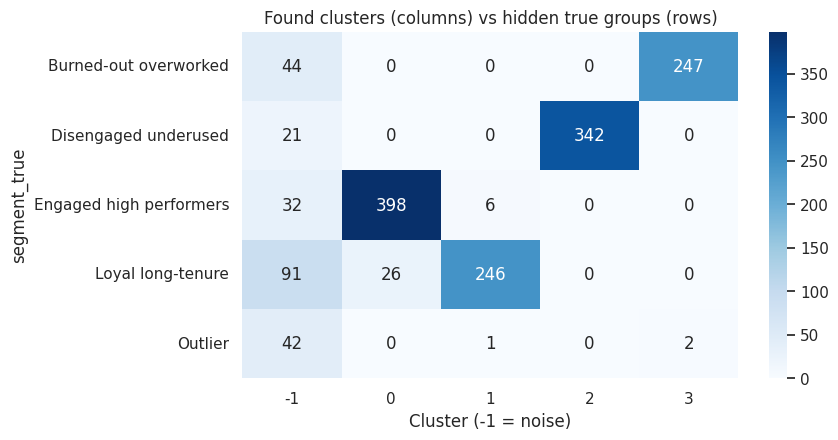

In [15]:
if HAS_TRUTH:
    plt.figure(figsize=(8, 4.5))
    sns.heatmap(pd.crosstab(df['segment_true'], labels), annot=True, fmt='d', cmap='Blues')
    plt.title('Found clusters (columns) vs hidden true groups (rows)'); plt.xlabel('Cluster (-1 = noise)'); plt.show()

**What to notice in this demo data (this run):**
- OPTICS finds **4 clusters**. Unlike DBSCAN and HDBSCAN (which merged them), it **separates** the two touching groups *Engaged high performers* and *Loyal long-tenure*. The reachability plot (section 6) shows why this is possible: one run gives the density structure at many `eps` levels.
- Like the other density methods it labels the unusual employees as noise: 42 of the 45 real random outliers are noise (-1).
- The noise (about 15%) also contains many *Loyal long-tenure* employees (long tenure is an unusual value), so **noise is not always "bad data"**.

### Cluster profile: who is in each cluster?
Green = high, red = low compared with the other clusters. Cluster -1 (if present) = noise / unusual employees.

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,size,share_%
cluster,,,,,,,,
-1,0.56,0.73,4.35,196.43,5.81,0.98,230,15.4
0,0.78,0.84,4.54,201.79,3.94,1.23,424,28.3
1,0.64,0.70,3.62,180.09,8.21,1.34,253,16.9
2,0.40,0.51,2.41,146.67,3.10,0.51,342,22.8
3,0.25,0.88,6.02,273.71,3.94,0.51,249,16.6


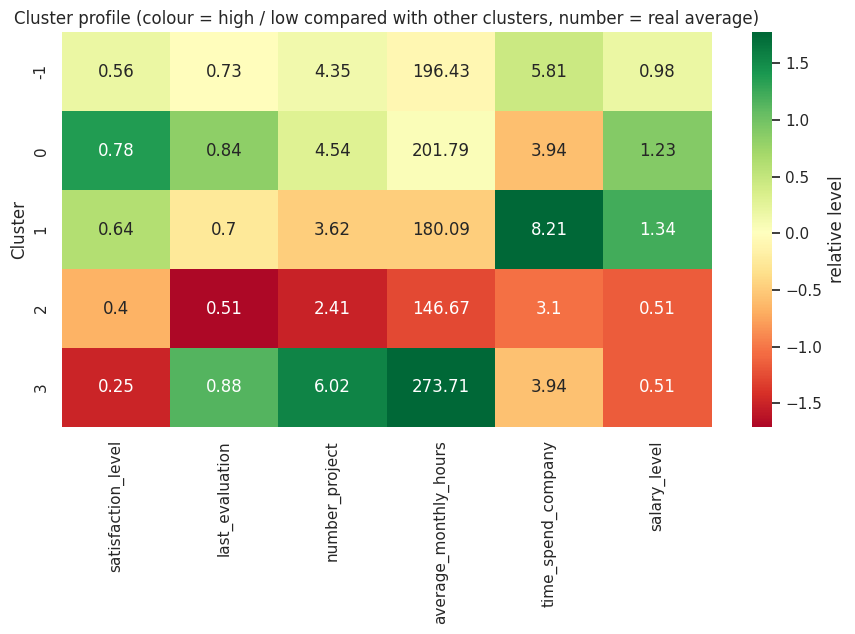

In [16]:
prof = cluster_profile(df, labels)
display(prof.round(2))
plot_profile(prof)

### Assign new employees and save
This algorithm has no `predict` method for new data. A common solution: train a small **KNN classifier on the found cluster labels** and use it to place new employees in the nearest cluster.

In [17]:
mask = labels != -1
assigner = KNeighborsClassifier(n_neighbors=5).fit(X[mask], labels[mask])

new = pd.DataFrame({'satisfaction_level': [0.15, 0.85, 0.45], 'last_evaluation': [0.90, 0.88, 0.50],
                    'number_project': [7, 5, 2], 'average_monthly_hours': [280, 210, 140],
                    'time_spend_company': [4, 3, 3]})
new['cluster'] = assigner.predict(scaler.transform(new[FEATURES]))
display(new)

joblib.dump({'scaler': scaler, 'model': optics, 'assigner': assigner, 'features': FEATURES, 'profile': prof}, 'optics_hr_model.pkl')
df.assign(cluster=labels).to_csv('hr_optics_clusters.csv', index=False)
print('Saved: optics_hr_model.pkl, hr_optics_clusters.csv')

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,cluster
0,0.15,0.90,7,280,4,3
1,0.85,0.88,5,210,3,0
2,0.45,0.50,2,140,3,2


Saved: optics_hr_model.pkl, hr_optics_clusters.csv


### Download (Google Colab only)

In [18]:
try:
    from google.colab import files
    files.download('optics_hr_model.pkl'); files.download('hr_optics_clusters.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
